# Lab 1 - Phần 1.3: Phân tích đơn biến, hai biến & công cụ EDA tự động
**Nội dung:** bài mẫu (chim cánh cụt, ydata-profiling, dtale) + Bài tập 1 (SweetViz) + Bài tập 2 (AutoViz) trên Marketing Campaign.

**Dữ liệu:** `penguins_size.csv`, `marketing_campaign.csv`

**Cài thư viện (nếu cần):** `pip install ydata-profiling dtale sweetviz autoviz`

In [1]:
import sys; sys.path.append(".")
from utils import *

## A. Bài làm mẫu - Chim cánh cụt (Palmer Penguins)

In [2]:
peng = load_table("penguins_size.csv", "penguins*.csv", "*penguin*.csv")
peng = peng.rename(columns={"bill_length_mm": "culmen_length_mm", "bill_depth_mm": "culmen_depth_mm"})
peng = peng[peng["sex"].isin(["MALE", "FEMALE", "Male", "Female"]) | peng["sex"].isna()]  # bỏ giá trị lạ '.'
overview(peng, "Penguins")
num_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]

[Đọc dữ liệu] data\penguins_size.csv
===== Penguins =====
Kích thước: 343 dòng x 7 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
species,object,0,0.00,3
island,object,0,0.00,3
culmen_length_mm,float64,2,0.58,164
culmen_depth_mm,float64,2,0.58,80
flipper_length_mm,float64,2,0.58,55
body_mass_g,float64,2,0.58,94
sex,object,10,2.92,2


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### A.1 Phân tích đơn biến (Univariate)
- **Biến số:** histogram, KDE, boxplot, violin + thống kê mô tả
- **Biến phân loại:** bảng tần số, countplot, pie

,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
culmen_length_mm,341,2,43.920,44.4,41.1,5.468,29.894,32.1,59.6,27.5,39.2,48.5,9.3,0.054,-0.882
culmen_depth_mm,341,2,17.155,17.3,17.0,1.976,3.905,13.1,21.5,8.4,15.6,18.7,3.1,-0.149,-0.906
flipper_length_mm,341,2,200.868,197.0,190.0,14.055,197.550,172.0,231.0,59.0,190.0,213.0,23.0,0.353,-0.975
body_mass_g,341,2,4199.780,4050.0,3800.0,802.300,643685.613,2700.0,6300.0,3600.0,3550.0,4750.0,1200.0,0.477,-0.713


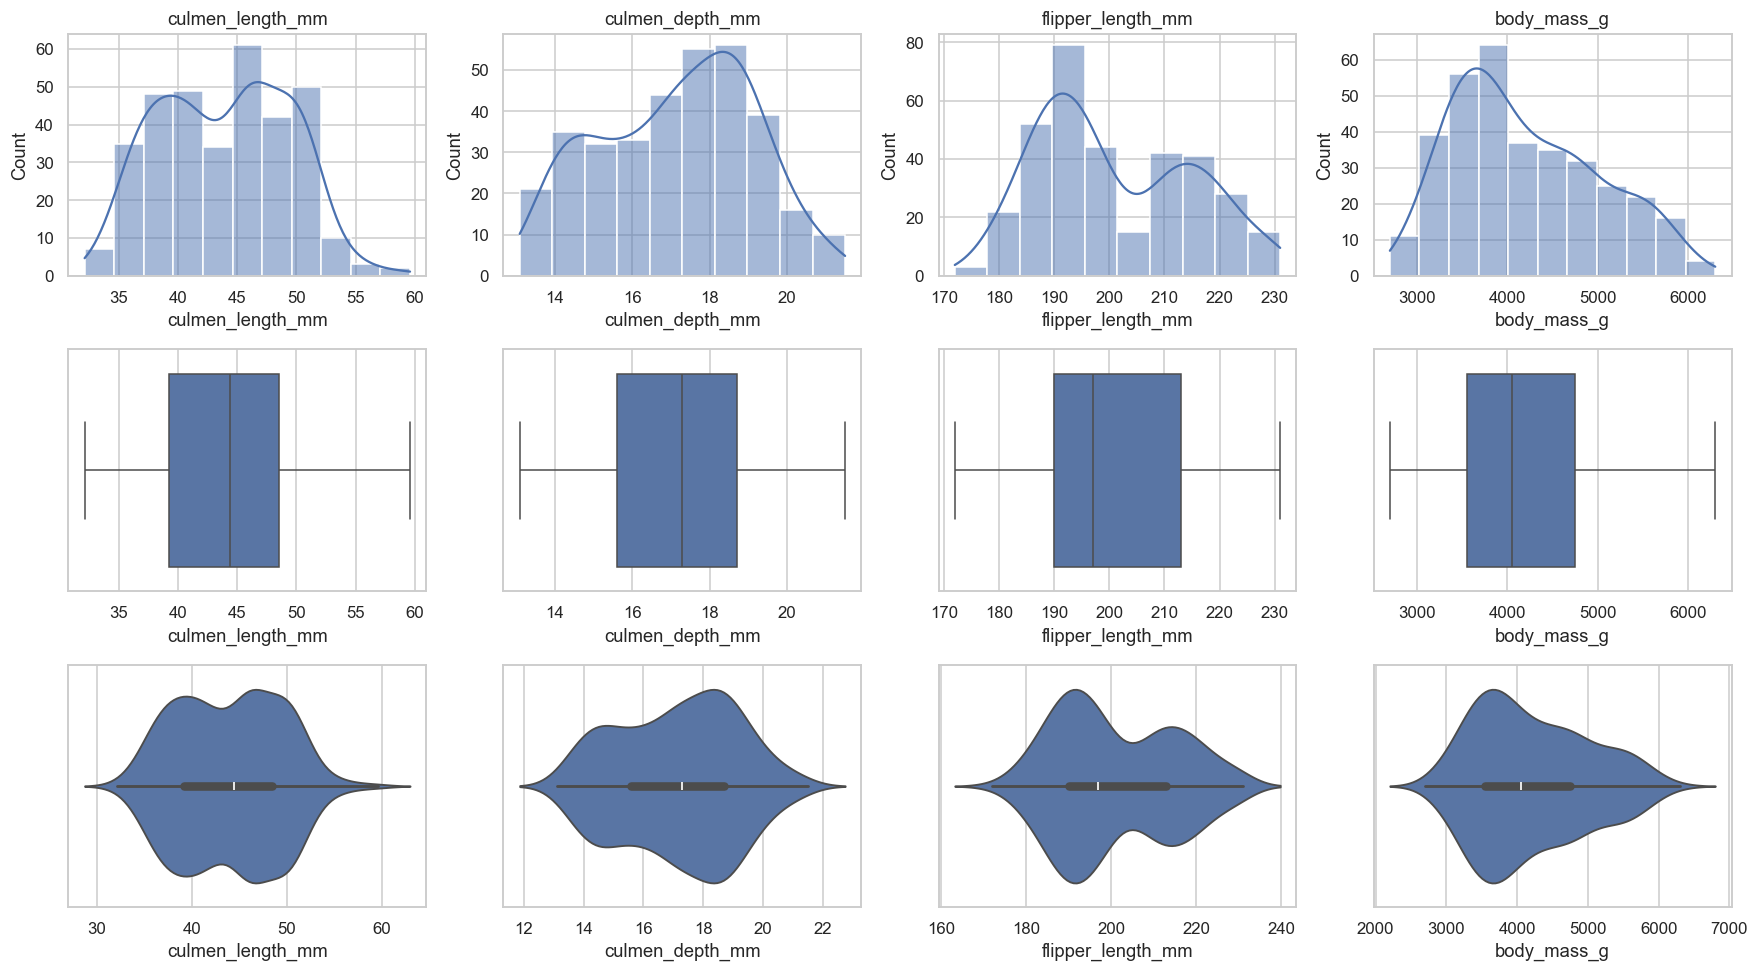

[Đã lưu] figures\s13_penguin_univariate_numeric.png


In [3]:
display(describe_full(peng[num_cols]))
fig, axs = plt.subplots(3, 4, figsize=(16, 9))
for i, c in enumerate(num_cols):
    sns.histplot(peng[c], kde=True, ax=axs[0, i])
    sns.boxplot(x=peng[c], ax=axs[1, i])
    sns.violinplot(x=peng[c], ax=axs[2, i])
    axs[0, i].set_title(c)
save_fig("s13_penguin_univariate_numeric")


Bảng tần số - species


,count
species,
Adelie,152
Gentoo,123
Chinstrap,68



Bảng tần số - island


,count
island,
Biscoe,167
Dream,124
Torgersen,52



Bảng tần số - sex


,count
sex,
MALE,168
FEMALE,165
NaN,10


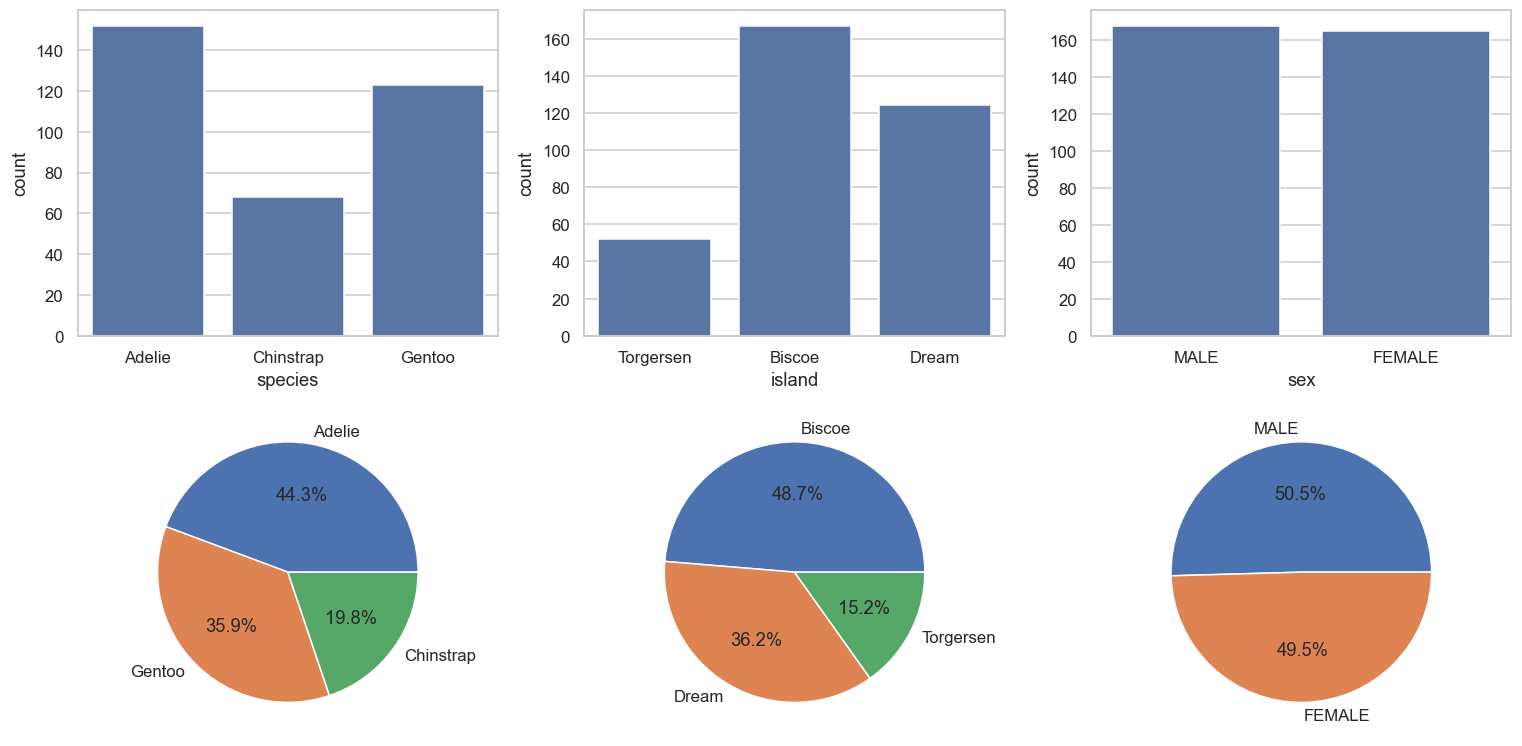

[Đã lưu] figures\s13_penguin_univariate_categorical.png


In [4]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(["species", "island", "sex"]):
    print(f"\nBảng tần số - {c}"); display(peng[c].value_counts(dropna=False).to_frame("count"))
    sns.countplot(data=peng, x=c, ax=axs[0, j])
    peng[c].value_counts().plot.pie(autopct="%1.1f%%", ax=axs[1, j], ylabel="")
save_fig("s13_penguin_univariate_categorical")

### A.2 Phân tích hai biến (Bivariate)
- số vs số: scatter, hệ số tương quan (Pearson / Spearman), hiệp phương sai
- số vs phân loại: boxplot/violin theo nhóm, pivot table
- phân loại vs phân loại: crosstab, stacked bar, chi-square

Hiệp phương sai (phụ thuộc đơn vị đo):


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,29.89,-2.54,50.50,2612.11
culmen_depth_mm,-2.54,3.91,-16.19,-746.69
flipper_length_mm,50.50,-16.19,197.55,9821.37
body_mass_g,2612.11,-746.69,9821.37,643685.61


Tương quan Pearson (không phụ thuộc đơn vị, -1..1):


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000,-0.235,0.657,0.595
culmen_depth_mm,-0.235,1.000,-0.583,-0.471
flipper_length_mm,0.657,-0.583,1.000,0.871
body_mass_g,0.595,-0.471,0.871,1.000


Tương quan Spearman (dựa trên thứ hạng, bền với ngoại lai):


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000,-0.221,0.674,0.584
culmen_depth_mm,-0.221,1.000,-0.521,-0.429
flipper_length_mm,0.674,-0.521,1.000,0.839
body_mass_g,0.584,-0.429,0.839,1.000


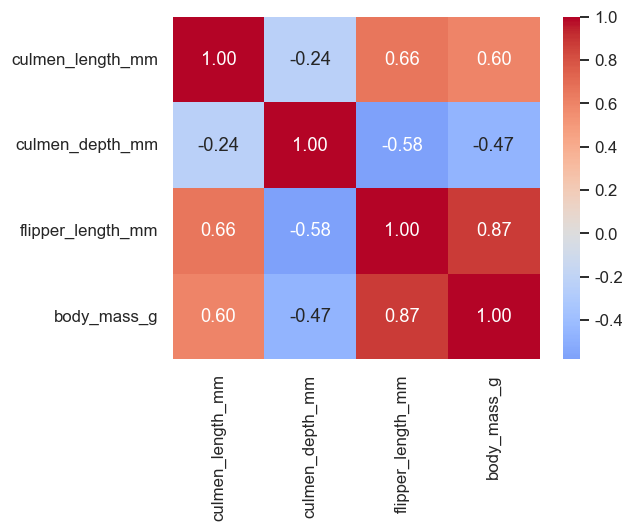

[Đã lưu] figures\s13_penguin_corr.png


In [5]:
print("Hiệp phương sai (phụ thuộc đơn vị đo):"); display(peng[num_cols].cov().round(2))
print("Tương quan Pearson (không phụ thuộc đơn vị, -1..1):"); display(peng[num_cols].corr().round(3))
print("Tương quan Spearman (dựa trên thứ hạng, bền với ngoại lai):"); display(peng[num_cols].corr(method="spearman").round(3))
plt.figure(figsize=(6, 5)); sns.heatmap(peng[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
save_fig("s13_penguin_corr")

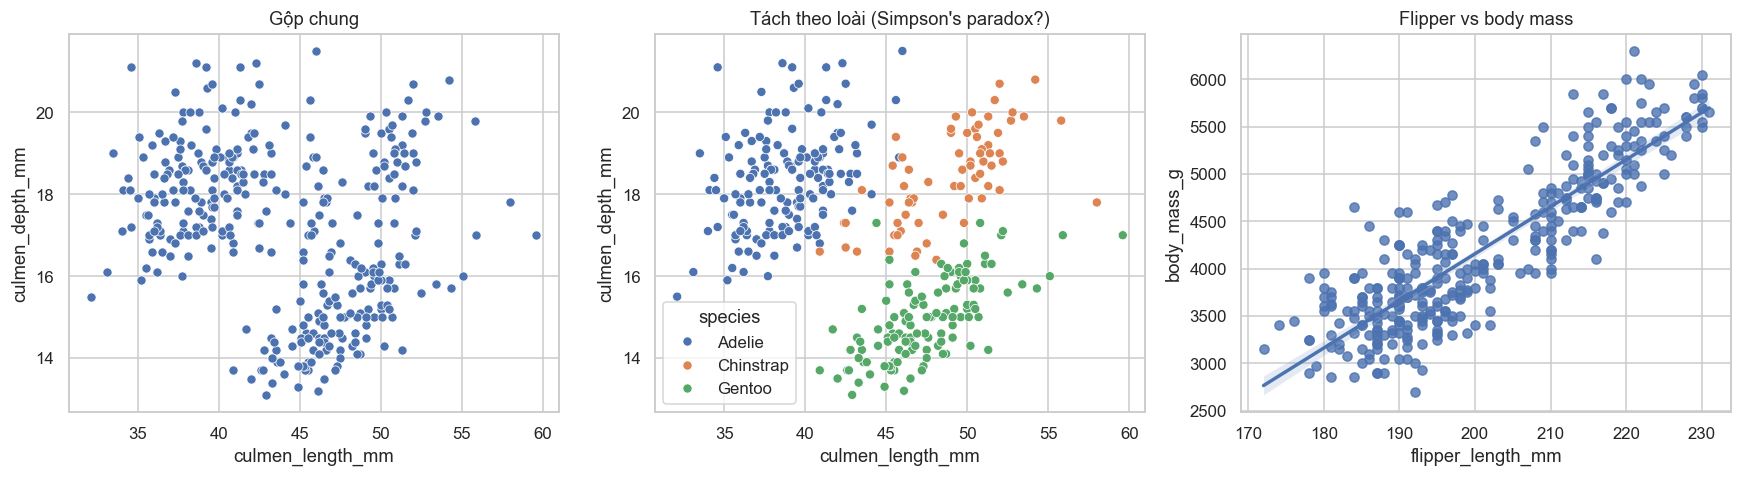

[Đã lưu] figures\s13_penguin_scatter.png


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=peng, x="culmen_length_mm", y="culmen_depth_mm", ax=axs[0]); axs[0].set_title("Gộp chung")
sns.scatterplot(data=peng, x="culmen_length_mm", y="culmen_depth_mm", hue="species", ax=axs[1]); axs[1].set_title("Tách theo loài (Simpson's paradox?)")
sns.regplot(data=peng, x="flipper_length_mm", y="body_mass_g", ax=axs[2]); axs[2].set_title("Flipper vs body mass")
save_fig("s13_penguin_scatter")

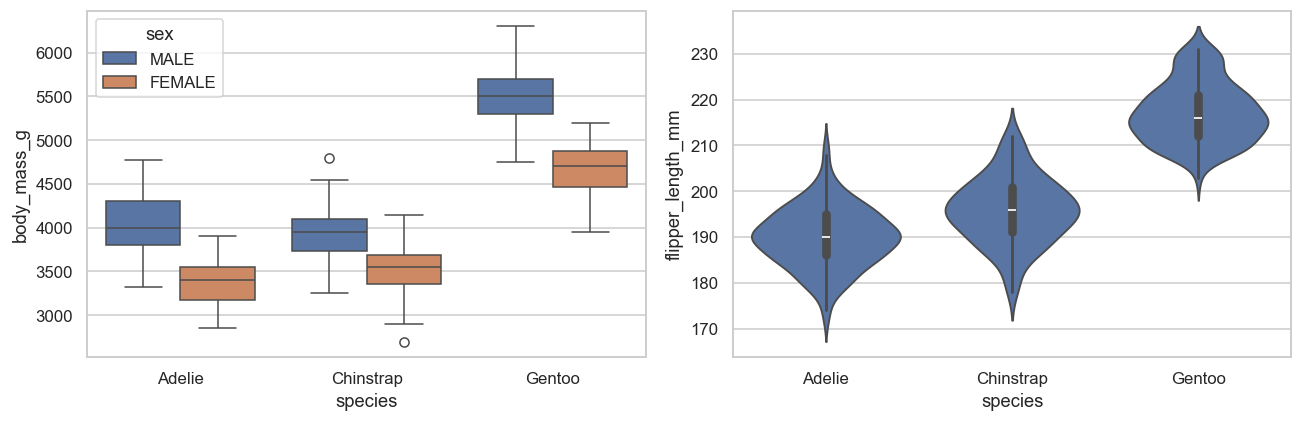

[Đã lưu] figures\s13_penguin_num_vs_cat.png
Pivot table - trung bình theo loài và đảo:


body_mass_g                   culmen_depth_mm                  \
island         Biscoe   Dream Torgersen          Biscoe Dream Torgersen   
species                                                                   
Adelie         3709.7  3688.4    3706.4            18.4  18.3      18.4   
Chinstrap         NaN  3733.1       NaN             NaN  18.4       NaN   
Gentoo         5077.7     NaN       NaN            15.0   NaN       NaN   

          culmen_length_mm                 flipper_length_mm                   
island              Biscoe Dream Torgersen            Biscoe  Dream Torgersen  
species                                                                        
Adelie                39.0  38.5      39.0             188.8  189.7     191.2  
Chinstrap              NaN  48.8       NaN               NaN  195.8       NaN  
Gentoo                47.5   NaN       NaN             217.2    NaN       NaN

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=peng, x="species", y="body_mass_g", hue="sex", ax=axs[0])
sns.violinplot(data=peng, x="species", y="flipper_length_mm", ax=axs[1])
save_fig("s13_penguin_num_vs_cat")
print("Pivot table - trung bình theo loài và đảo:")
display(peng.pivot_table(values=num_cols, index="species", columns="island", aggfunc="mean").round(1))

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,123,0,0


Chi-square = 298.30, p-value = 2.52e-63 -> có liên hệ giữa species và island (alpha = 0.05)


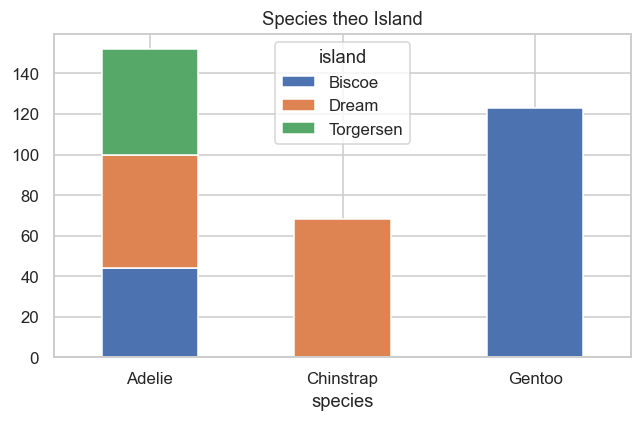

[Đã lưu] figures\s13_penguin_crosstab.png


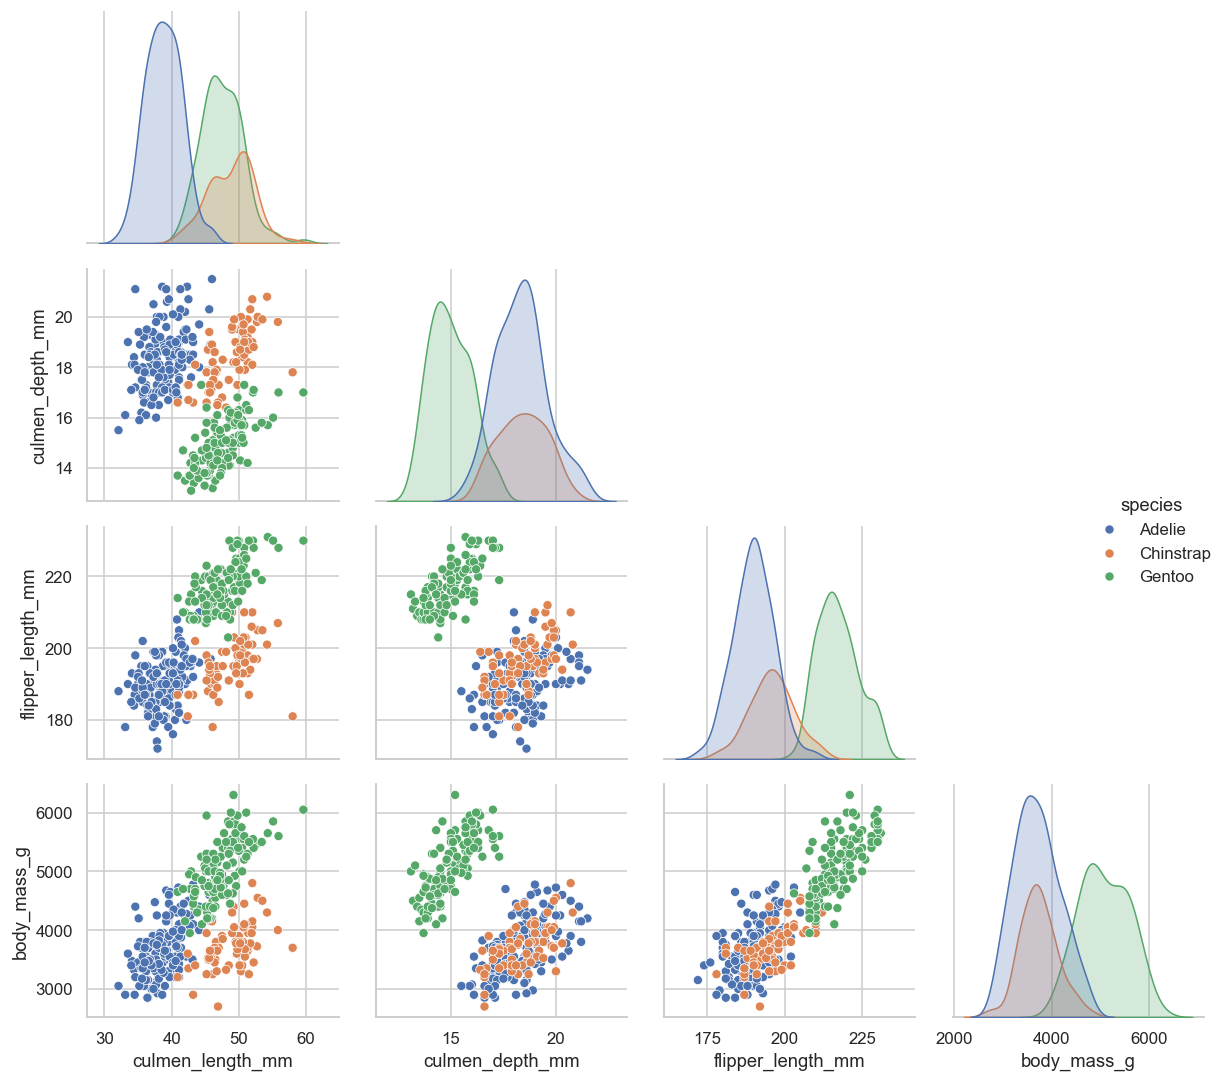

[Đã lưu] figures\s13_penguin_pairplot.png


In [8]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(peng["species"], peng["island"]); display(ct)
chi2, p, dof, _ = chi2_contingency(ct)
print(f"Chi-square = {chi2:.2f}, p-value = {p:.3g} -> {'có' if p < .05 else 'không có'} liên hệ giữa species và island (alpha = 0.05)")
ct.plot.bar(stacked=True, figsize=(6, 4), rot=0); plt.title("Species theo Island")
save_fig("s13_penguin_crosstab")
sns.pairplot(peng[num_cols + ["species"]].dropna(), hue="species", corner=True)
save_fig("s13_penguin_pairplot")

## B. Công cụ EDA tự động (bài mẫu)
### Dữ liệu Marketing Campaign

In [9]:
mk = load_table("marketing_campaign.csv", "*marketing*.csv")
mk = mk.drop_duplicates().copy()
mk["Dt_Customer"] = pd.to_datetime(mk["Dt_Customer"], dayfirst=True, errors="coerce")
mk["Age"] = 2024 - mk["Year_Birth"]
spend_cols = [c for c in mk.columns if c.startswith("Mnt")]
if spend_cols:
    mk["Total_Spent"] = mk[spend_cols].sum(axis=1)
overview(mk, "Marketing Campaign")

[Đọc dữ liệu] data\marketing_campaign.csv
===== Marketing Campaign =====
Kích thước: 2240 dòng x 31 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
ID,int64,0,0.00,2240
Year_Birth,int64,0,0.00,59
Education,object,0,0.00,5
Marital_Status,object,0,0.00,8
Income,float64,24,1.07,1974
Kidhome,int64,0,0.00,3
Teenhome,int64,0,0.00,3
Dt_Customer,datetime64[ns],0,0.00,663
Recency,int64,0,0.00,100
MntWines,int64,0,0.00,776


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_Spent
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,3,11,1,67,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,3,11,0,70,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,3,11,0,59,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,3,11,0,40,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,3,11,0,43,422


**ydata-profiling** (tạo báo cáo HTML đầy đủ: overview, variables, interactions, correlations, missing, alerts)

In [10]:
try:
    from ydata_profiling import ProfileReport
    profile = ProfileReport(mk, title="Marketing Campaign - ydata-profiling", explorative=True)
    profile.to_file(OUT_DIR / "profile_output.html")
    print("Đã lưu outputs/profile_output.html")
except ImportError:
    print("Chưa cài ydata-profiling: pip install ydata-profiling")
except Exception as e:
    print("ydata-profiling lỗi:", e)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 31/31 [00:00<00:00, 422.48it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu outputs/profile_output.html


**dtale** (giao diện web tương tác trên dataframe)

In [11]:
try:
    import dtale
    d = dtale.show(mk, host="localhost")
    print("Mở dtale tại:", d._main_url)
except ImportError:
    print("Chưa cài dtale: pip install dtale")
except Exception as e:
    print("dtale lỗi:", e)

Mở dtale tại: http://localhost:40000/dtale/main/1


## C. Bài tập 1 - SweetViz

In [12]:
try:
    import sweetviz as sv
    tgt = "Response" if "Response" in mk.columns else None
    rep = sv.analyze(mk, target_feat=tgt)
    rep.show_html(str(OUT_DIR / "sweetviz_report.html"), open_browser=False)
    if "Kidhome" in mk.columns:
        a = mk[mk["Kidhome"] == 0].drop(columns="Kidhome")
        b = mk[mk["Kidhome"] > 0].drop(columns="Kidhome")
        cmp_rep = sv.compare([a, "Không có trẻ nhỏ"], [b, "Có trẻ nhỏ"])
        cmp_rep.show_html(str(OUT_DIR / "sweetviz_compare.html"), open_browser=False)
    print("Đã lưu outputs/sweetviz_report.html và sweetviz_compare.html")
except ImportError:
    print("Chưa cài sweetviz: pip install sweetviz")
except Exception as e:
    print("sweetviz lỗi:", e)

                                             |          | [  0%]   00:00 -> (? left)

Report D:\MayHoc\Lab05_Code\Lab05_ModelTraining\outputs\sweetviz_report.html was generated.


                                             |          | [  0%]   00:00 -> (? left)

Report D:\MayHoc\Lab05_Code\Lab05_ModelTraining\outputs\sweetviz_compare.html was generated.
Đã lưu outputs/sweetviz_report.html và sweetviz_compare.html


## D. Bài tập 2 - AutoViz

Shape of your Data Set loaded: (2240, 31)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
  Printing up to 30 columns (max) in each category:
    Numeric Columns : ['Income']
    Integer-Categorical Columns: ['Year_Birth', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Total_Spent']
    String-Categorical Columns: ['Education', 'Marital_Status']
    Factor-Categorical Columns: []
    String-Boolean Columns: []
    Numeric-Boolean Columns: ['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response']


,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
ID,int64,0.000000,100,0.000000,11191.000000,Possible ID column: drop before modeling step.
Year_Birth,int64,0.000000,2,1893.000000,1996.000000,Column has 3 outliers greater than upper bound (2004.00) or lower than lower bound(1932.00). Cap them or remove them.
Education,object,0.000000,0,,,No issue
Marital_Status,object,0.000000,0,,,"3 rare categories: ['Alone', 'Absurd', 'YOLO']. Group them into a single category or drop the categories."
Income,float64,1.071429,NA,1730.000000,666666.000000,"24 missing values. Impute them with mean, median, mode, or a constant value such as 123., Column has 8 outliers greater than upper bound (118350.50) or lower than lower bound(-14525.50). Cap them or remove them."
Kidhome,int64,0.000000,0,0.000000,2.000000,No issue
Teenhome,int64,0.000000,0,0.000000,2.000000,No issue
Dt_Customer,datetime64[ns],0.000000,29,,,Possible date-time colum: transform before modeling step.
Recency,int64,0.000000,4,0.000000,99.000000,No issue
MntWines,int64,0.000000,34,0.000000,1493.000000,Column has 35 outliers greater than upper bound (1225.00) or lower than lower bound(-697.00). Cap them or remove them.


Could not draw Date Vars tile cannot extend outside image
All Plots are saved in D:\MayHoc\Lab05_Code\Lab05_ModelTraining\outputs\autoviz\AutoViz
Time to run AutoViz = 5 seconds 
Biểu đồ AutoViz đã lưu trong D:\MayHoc\Lab05_Code\Lab05_ModelTraining\outputs\autoviz


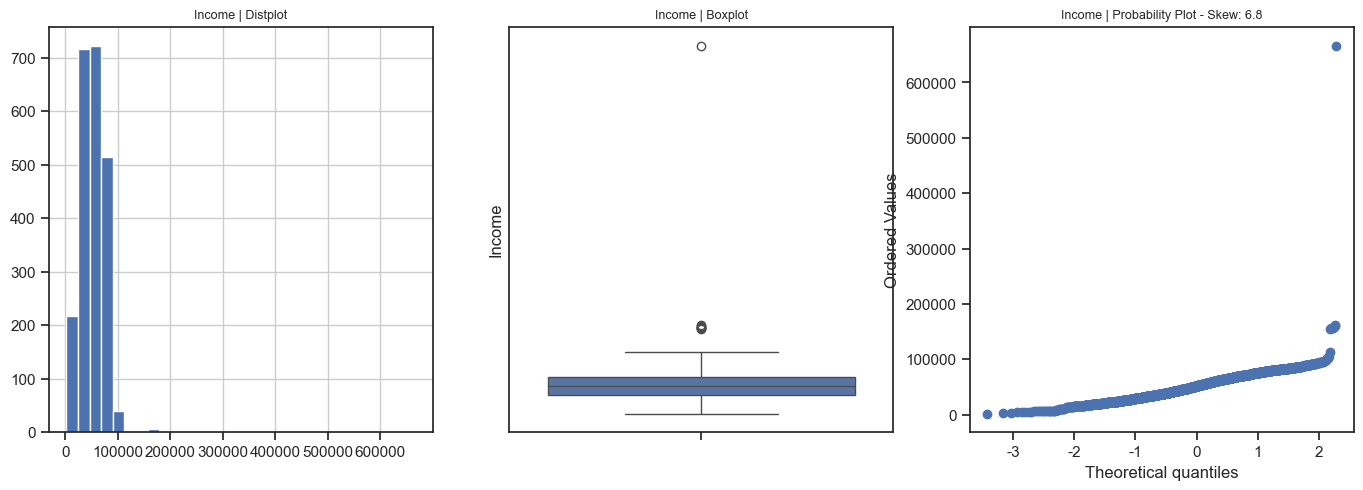

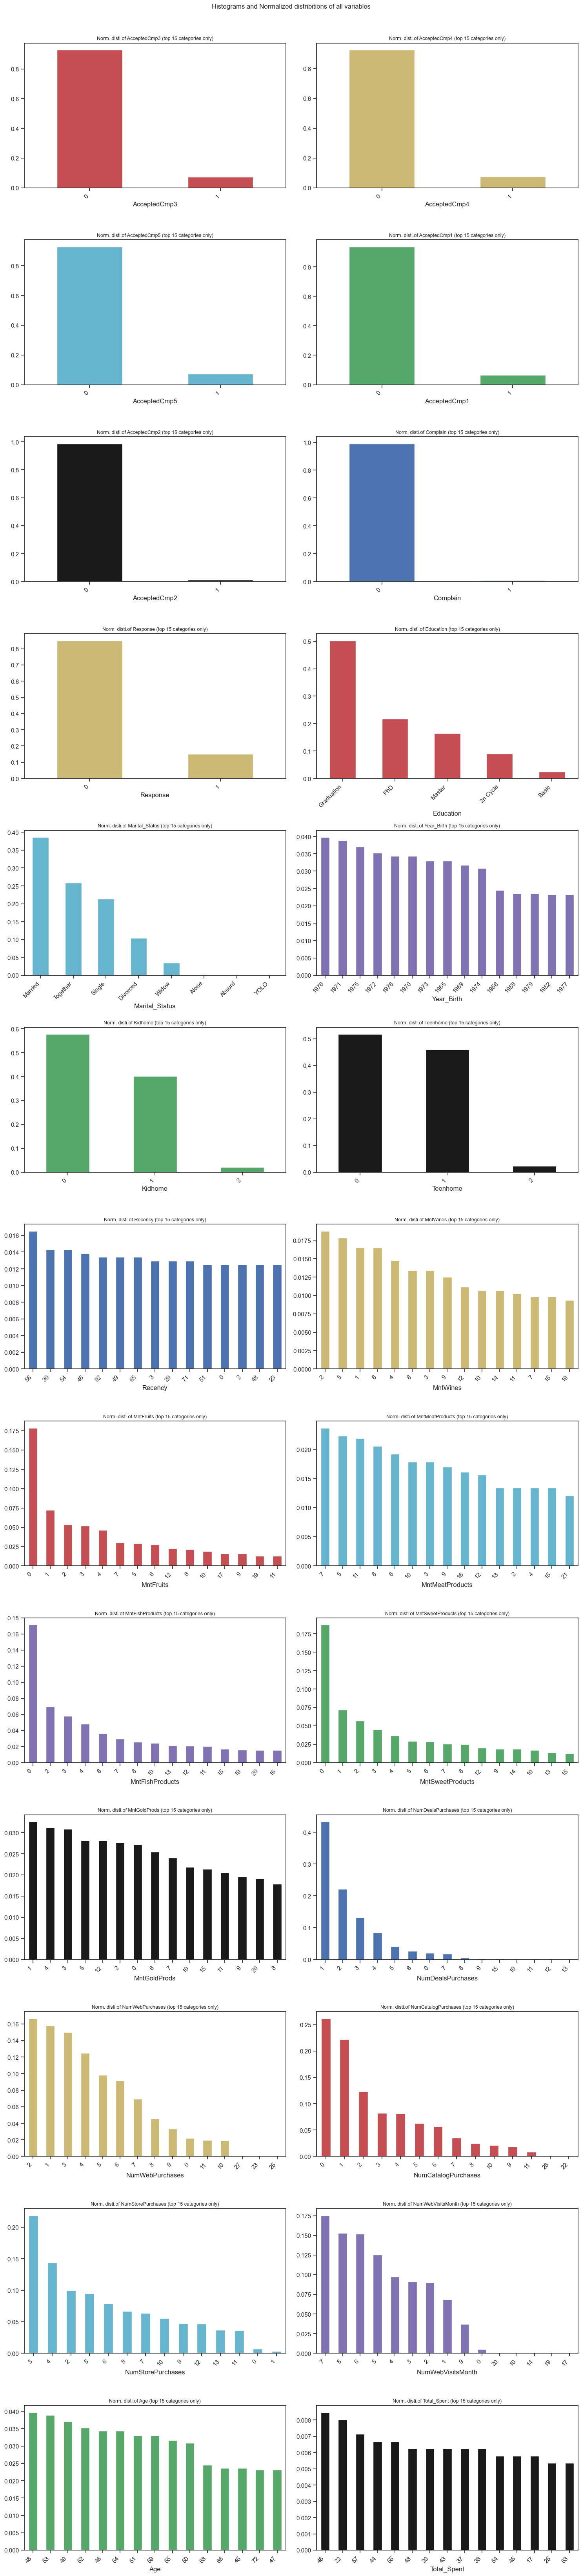

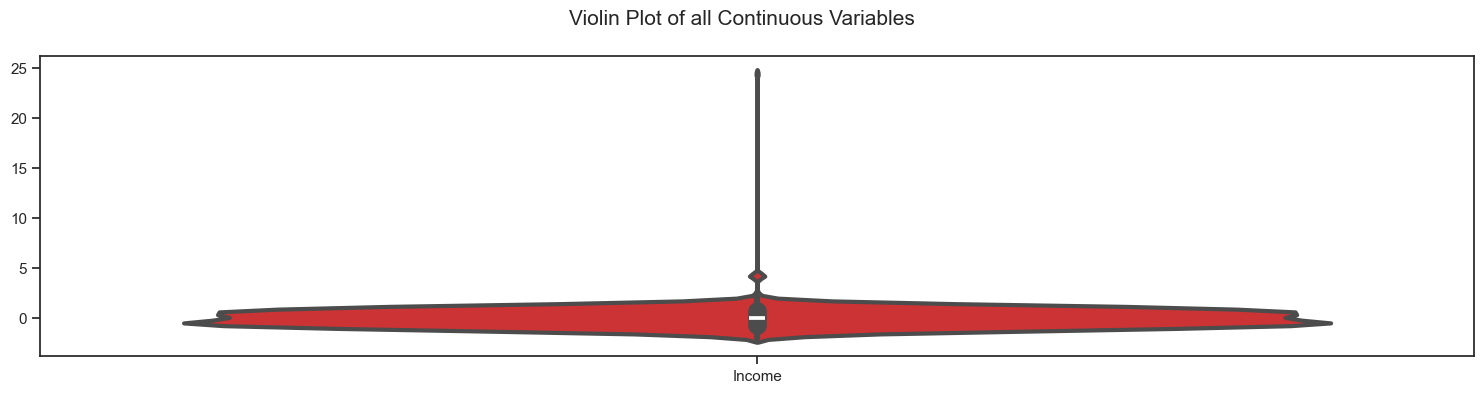

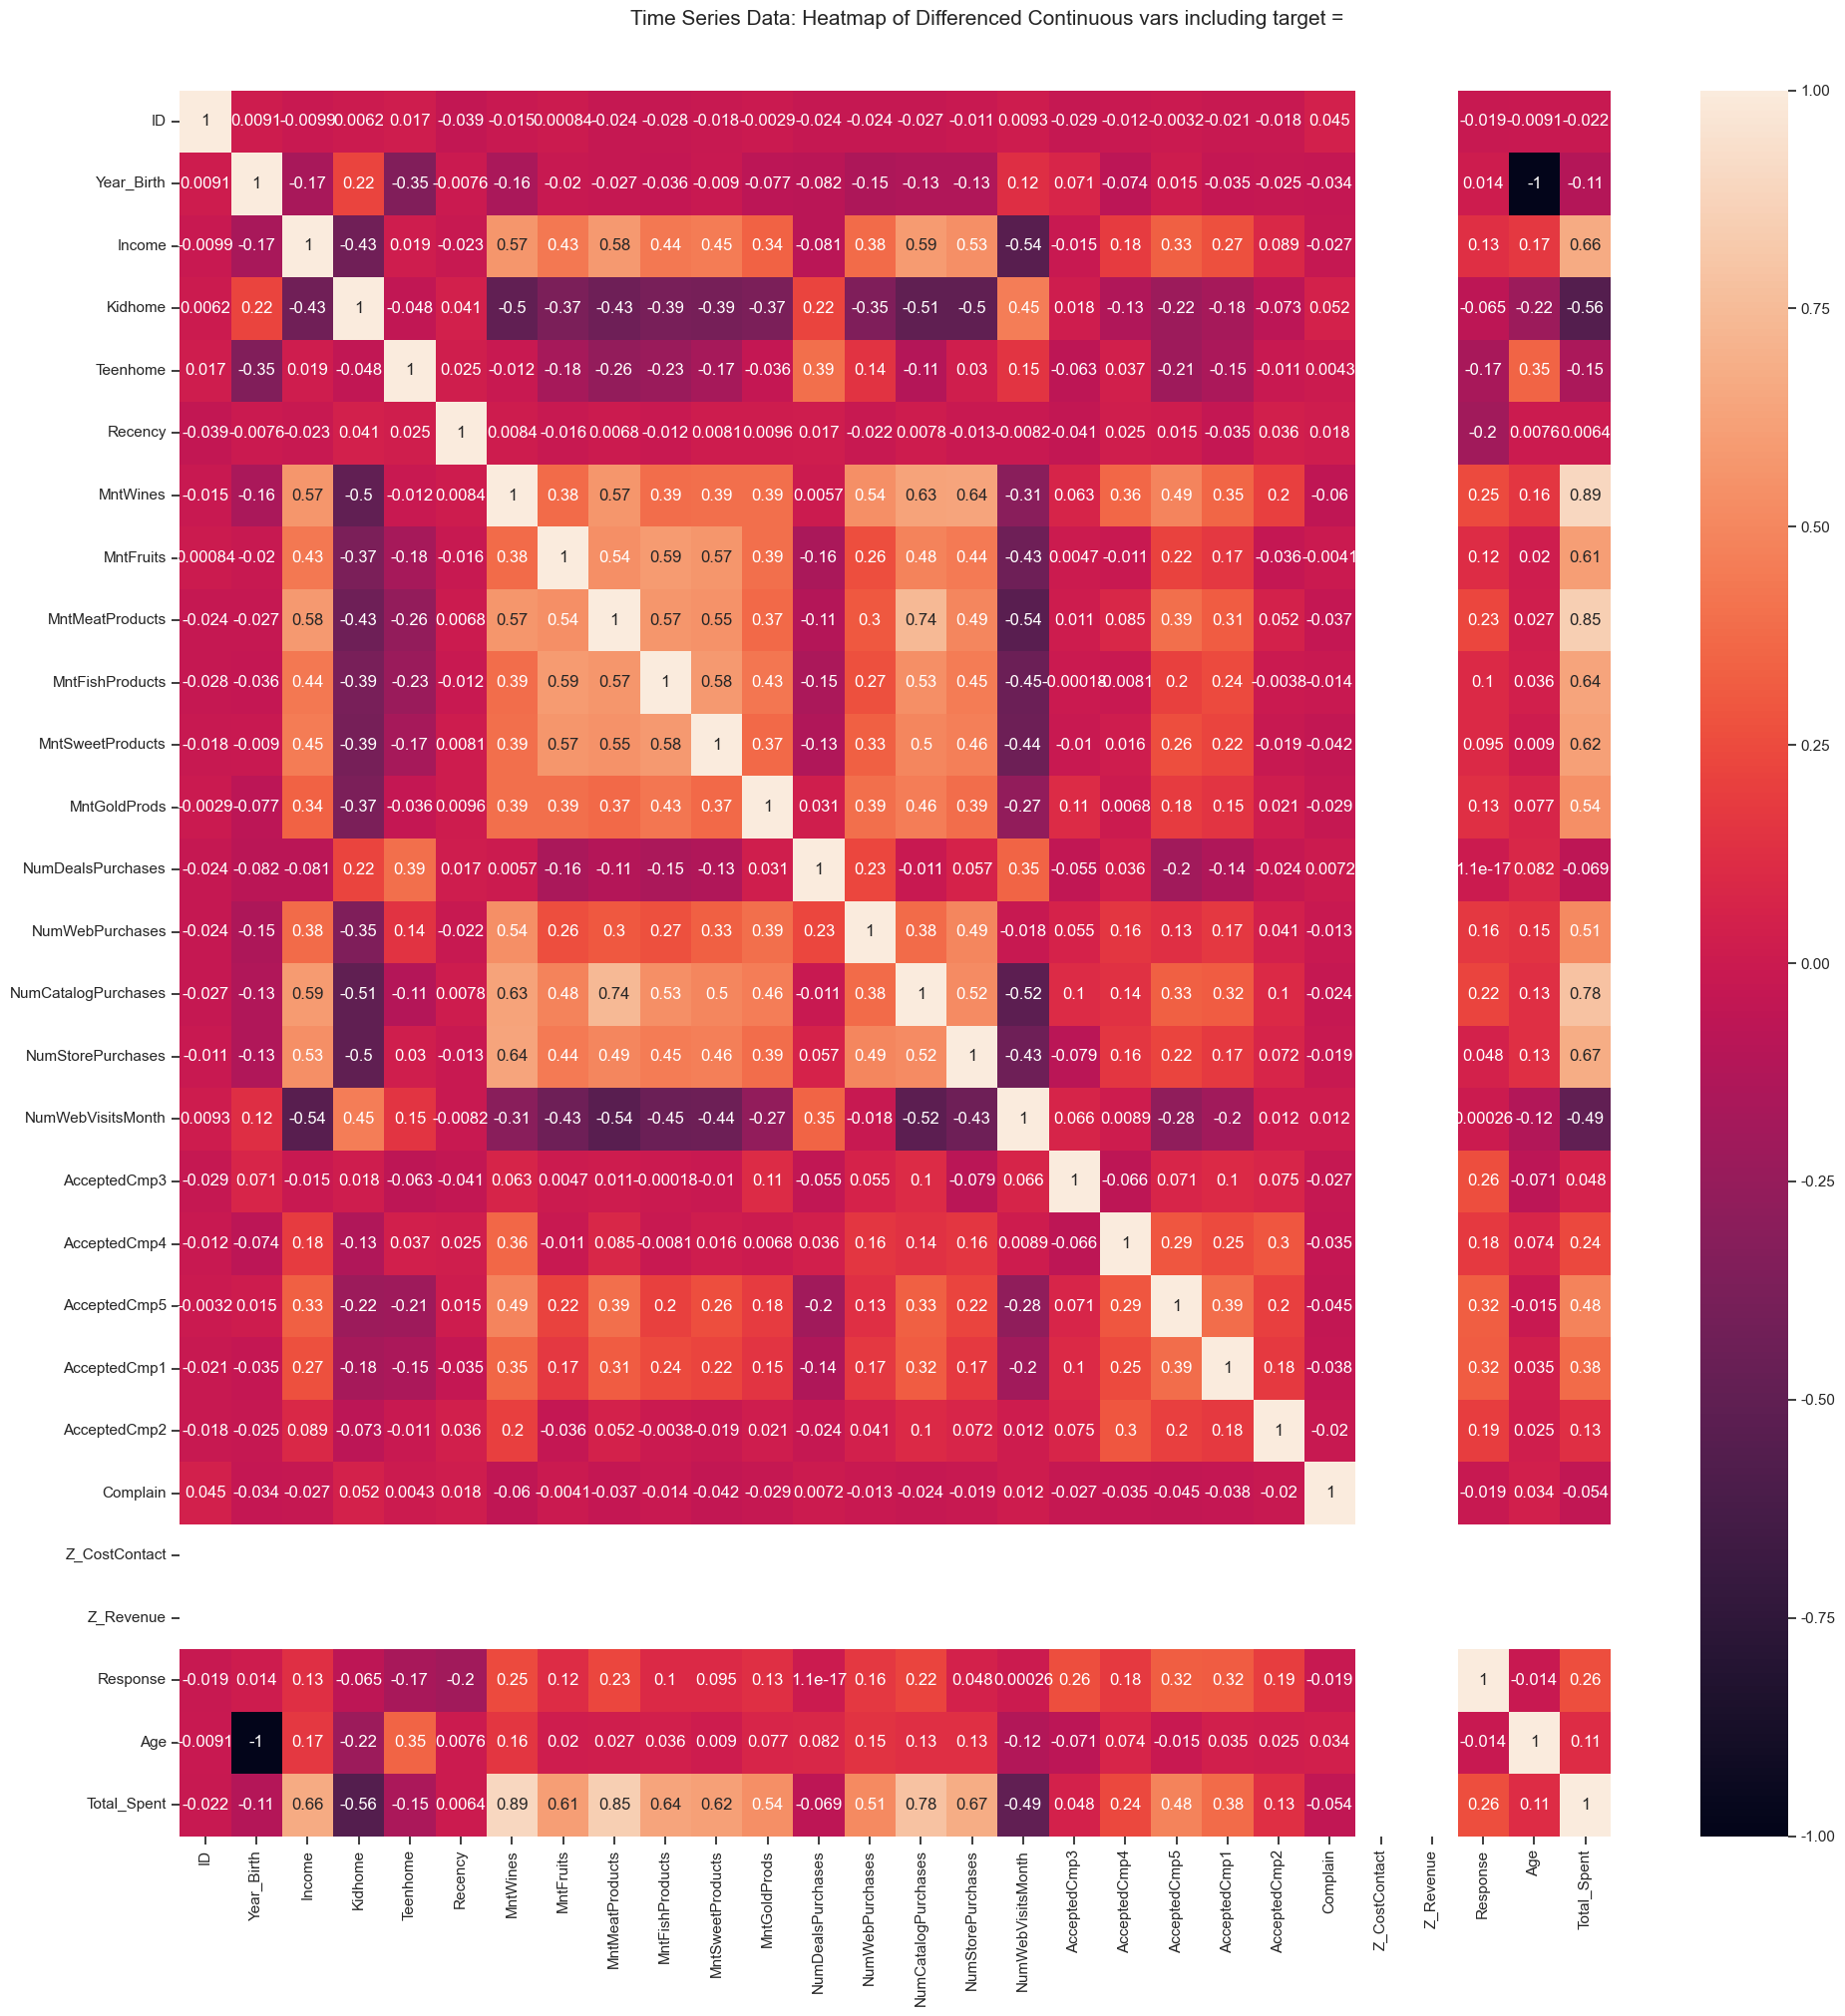

<Figure size 1500x0 with 0 Axes>

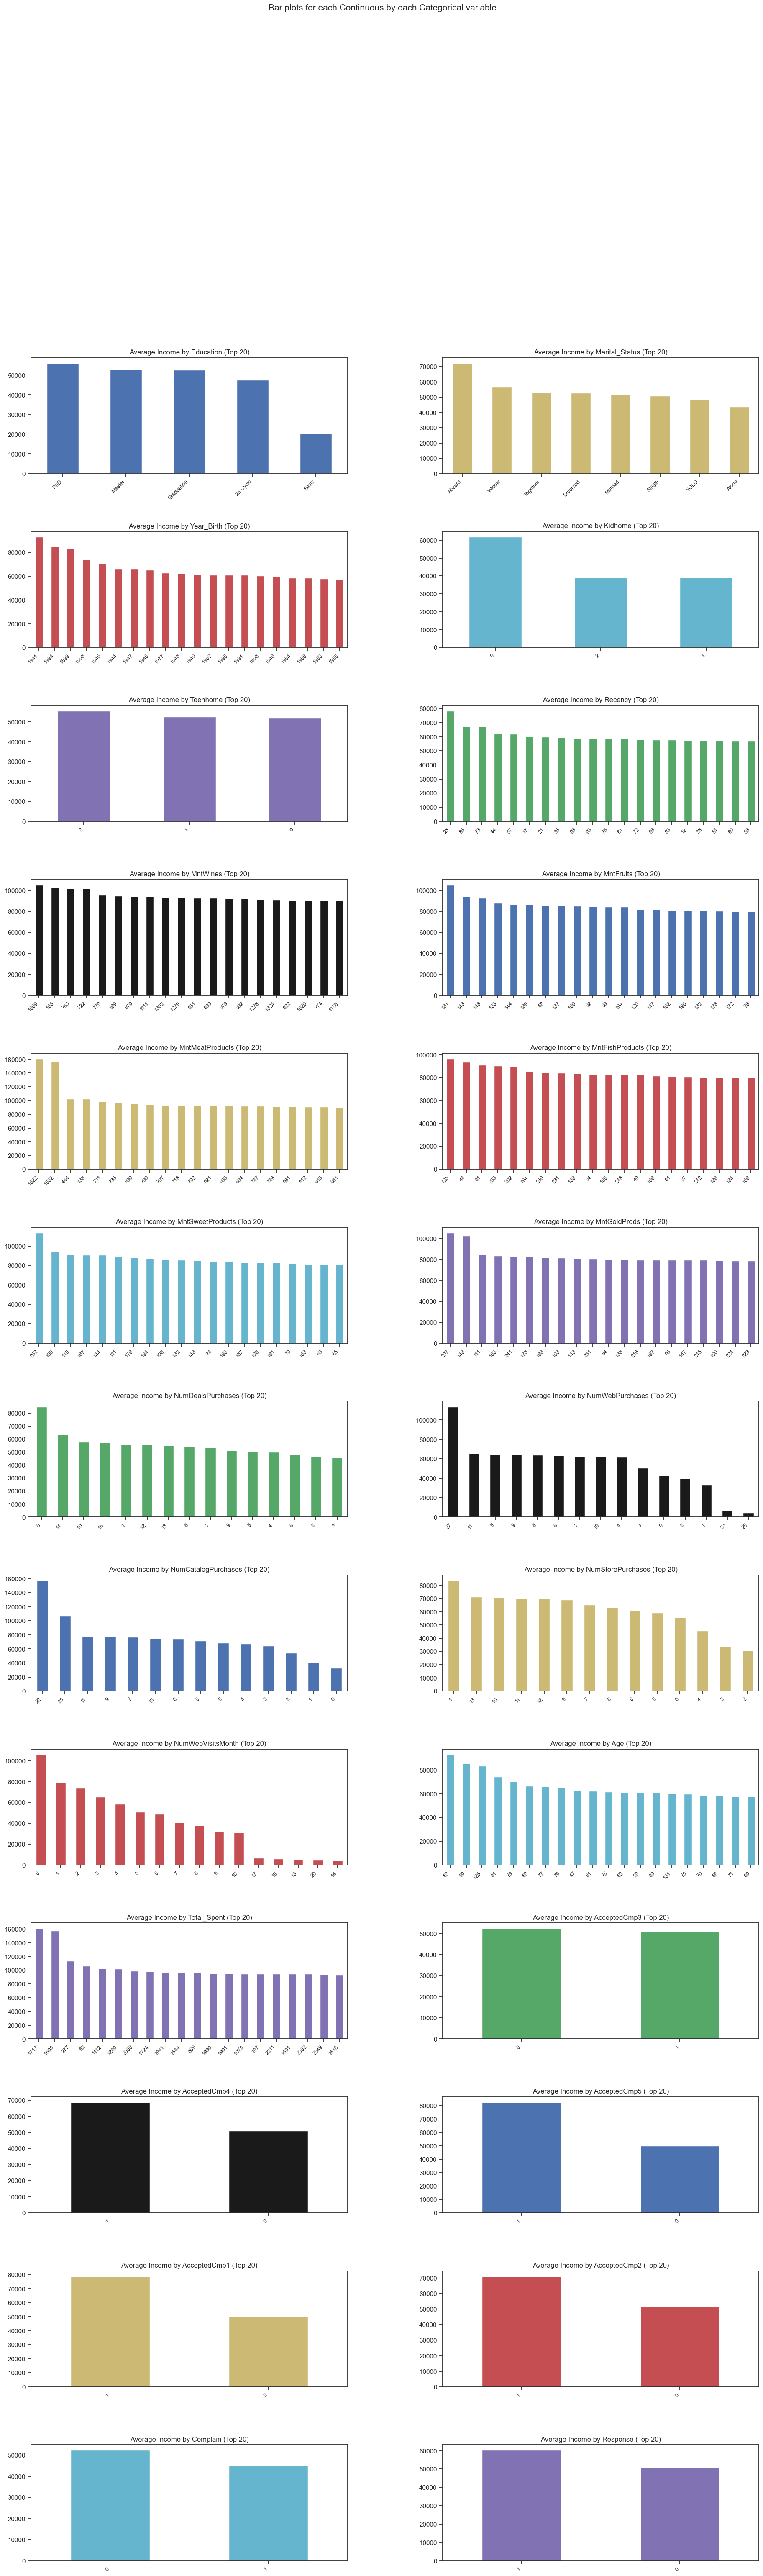

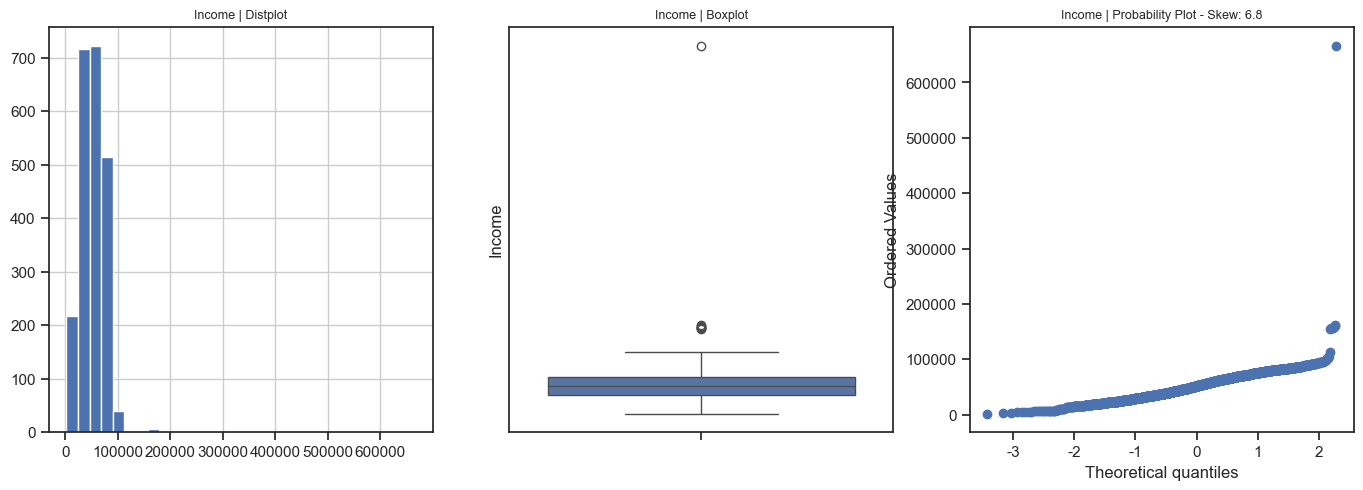

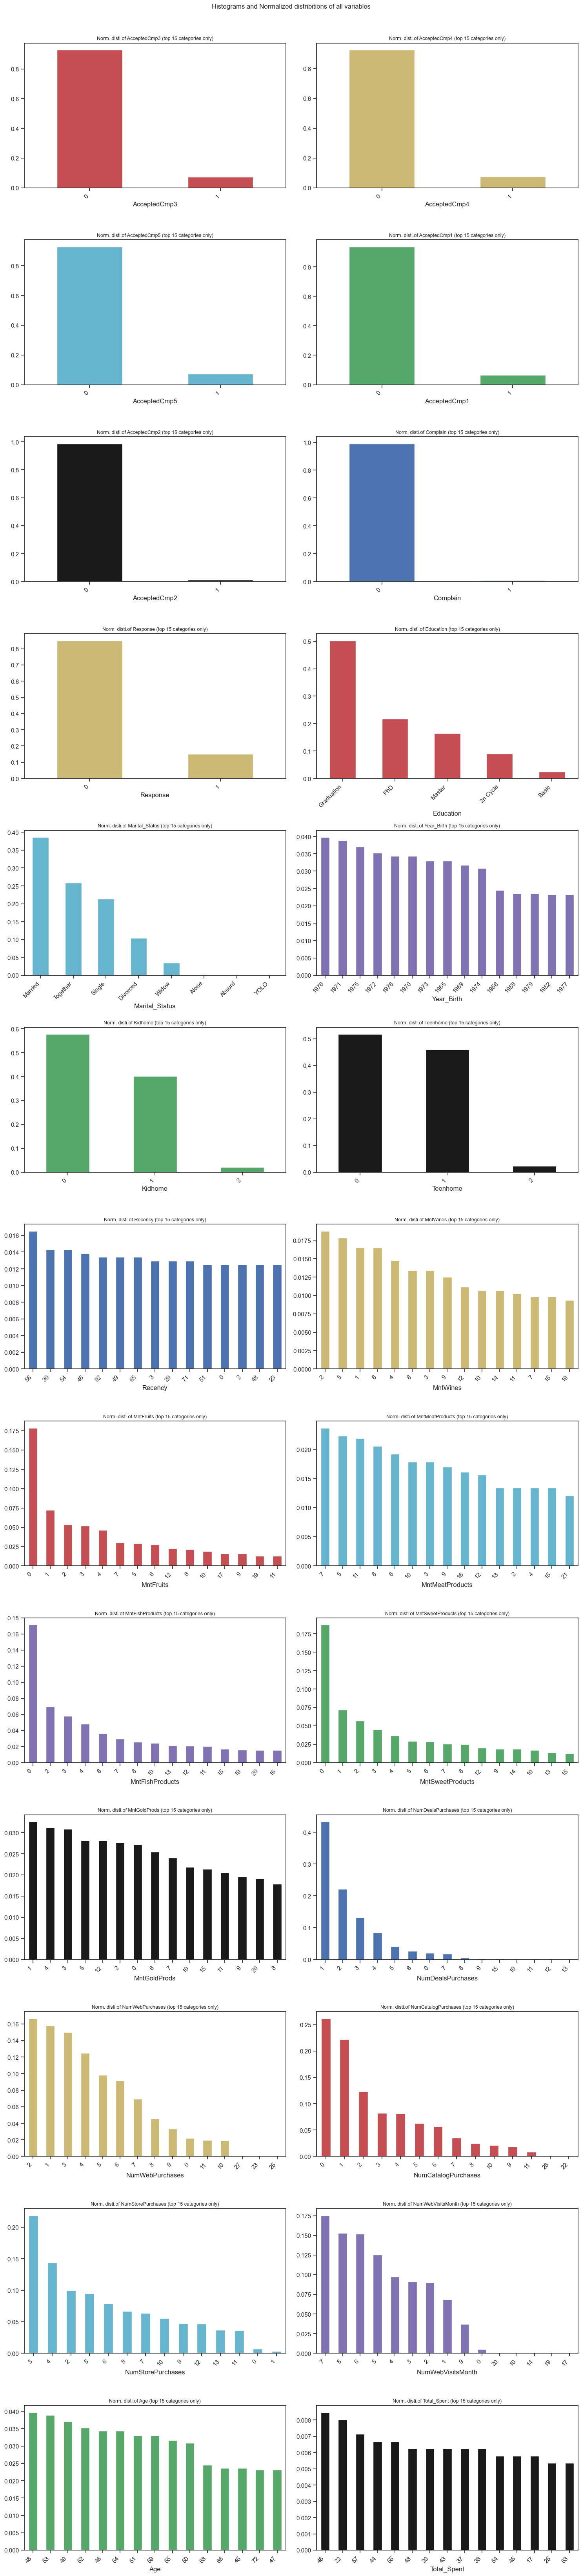

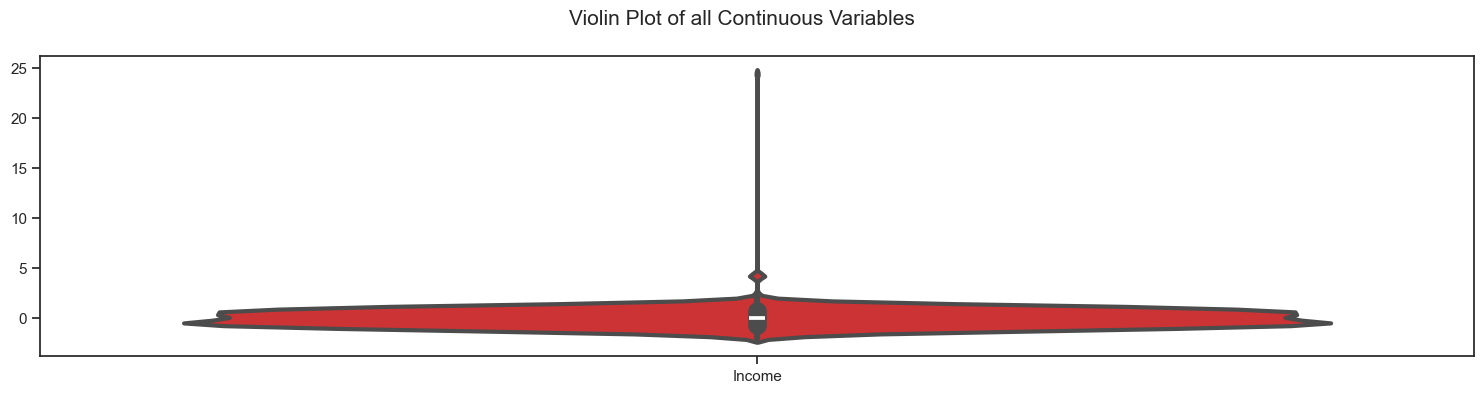

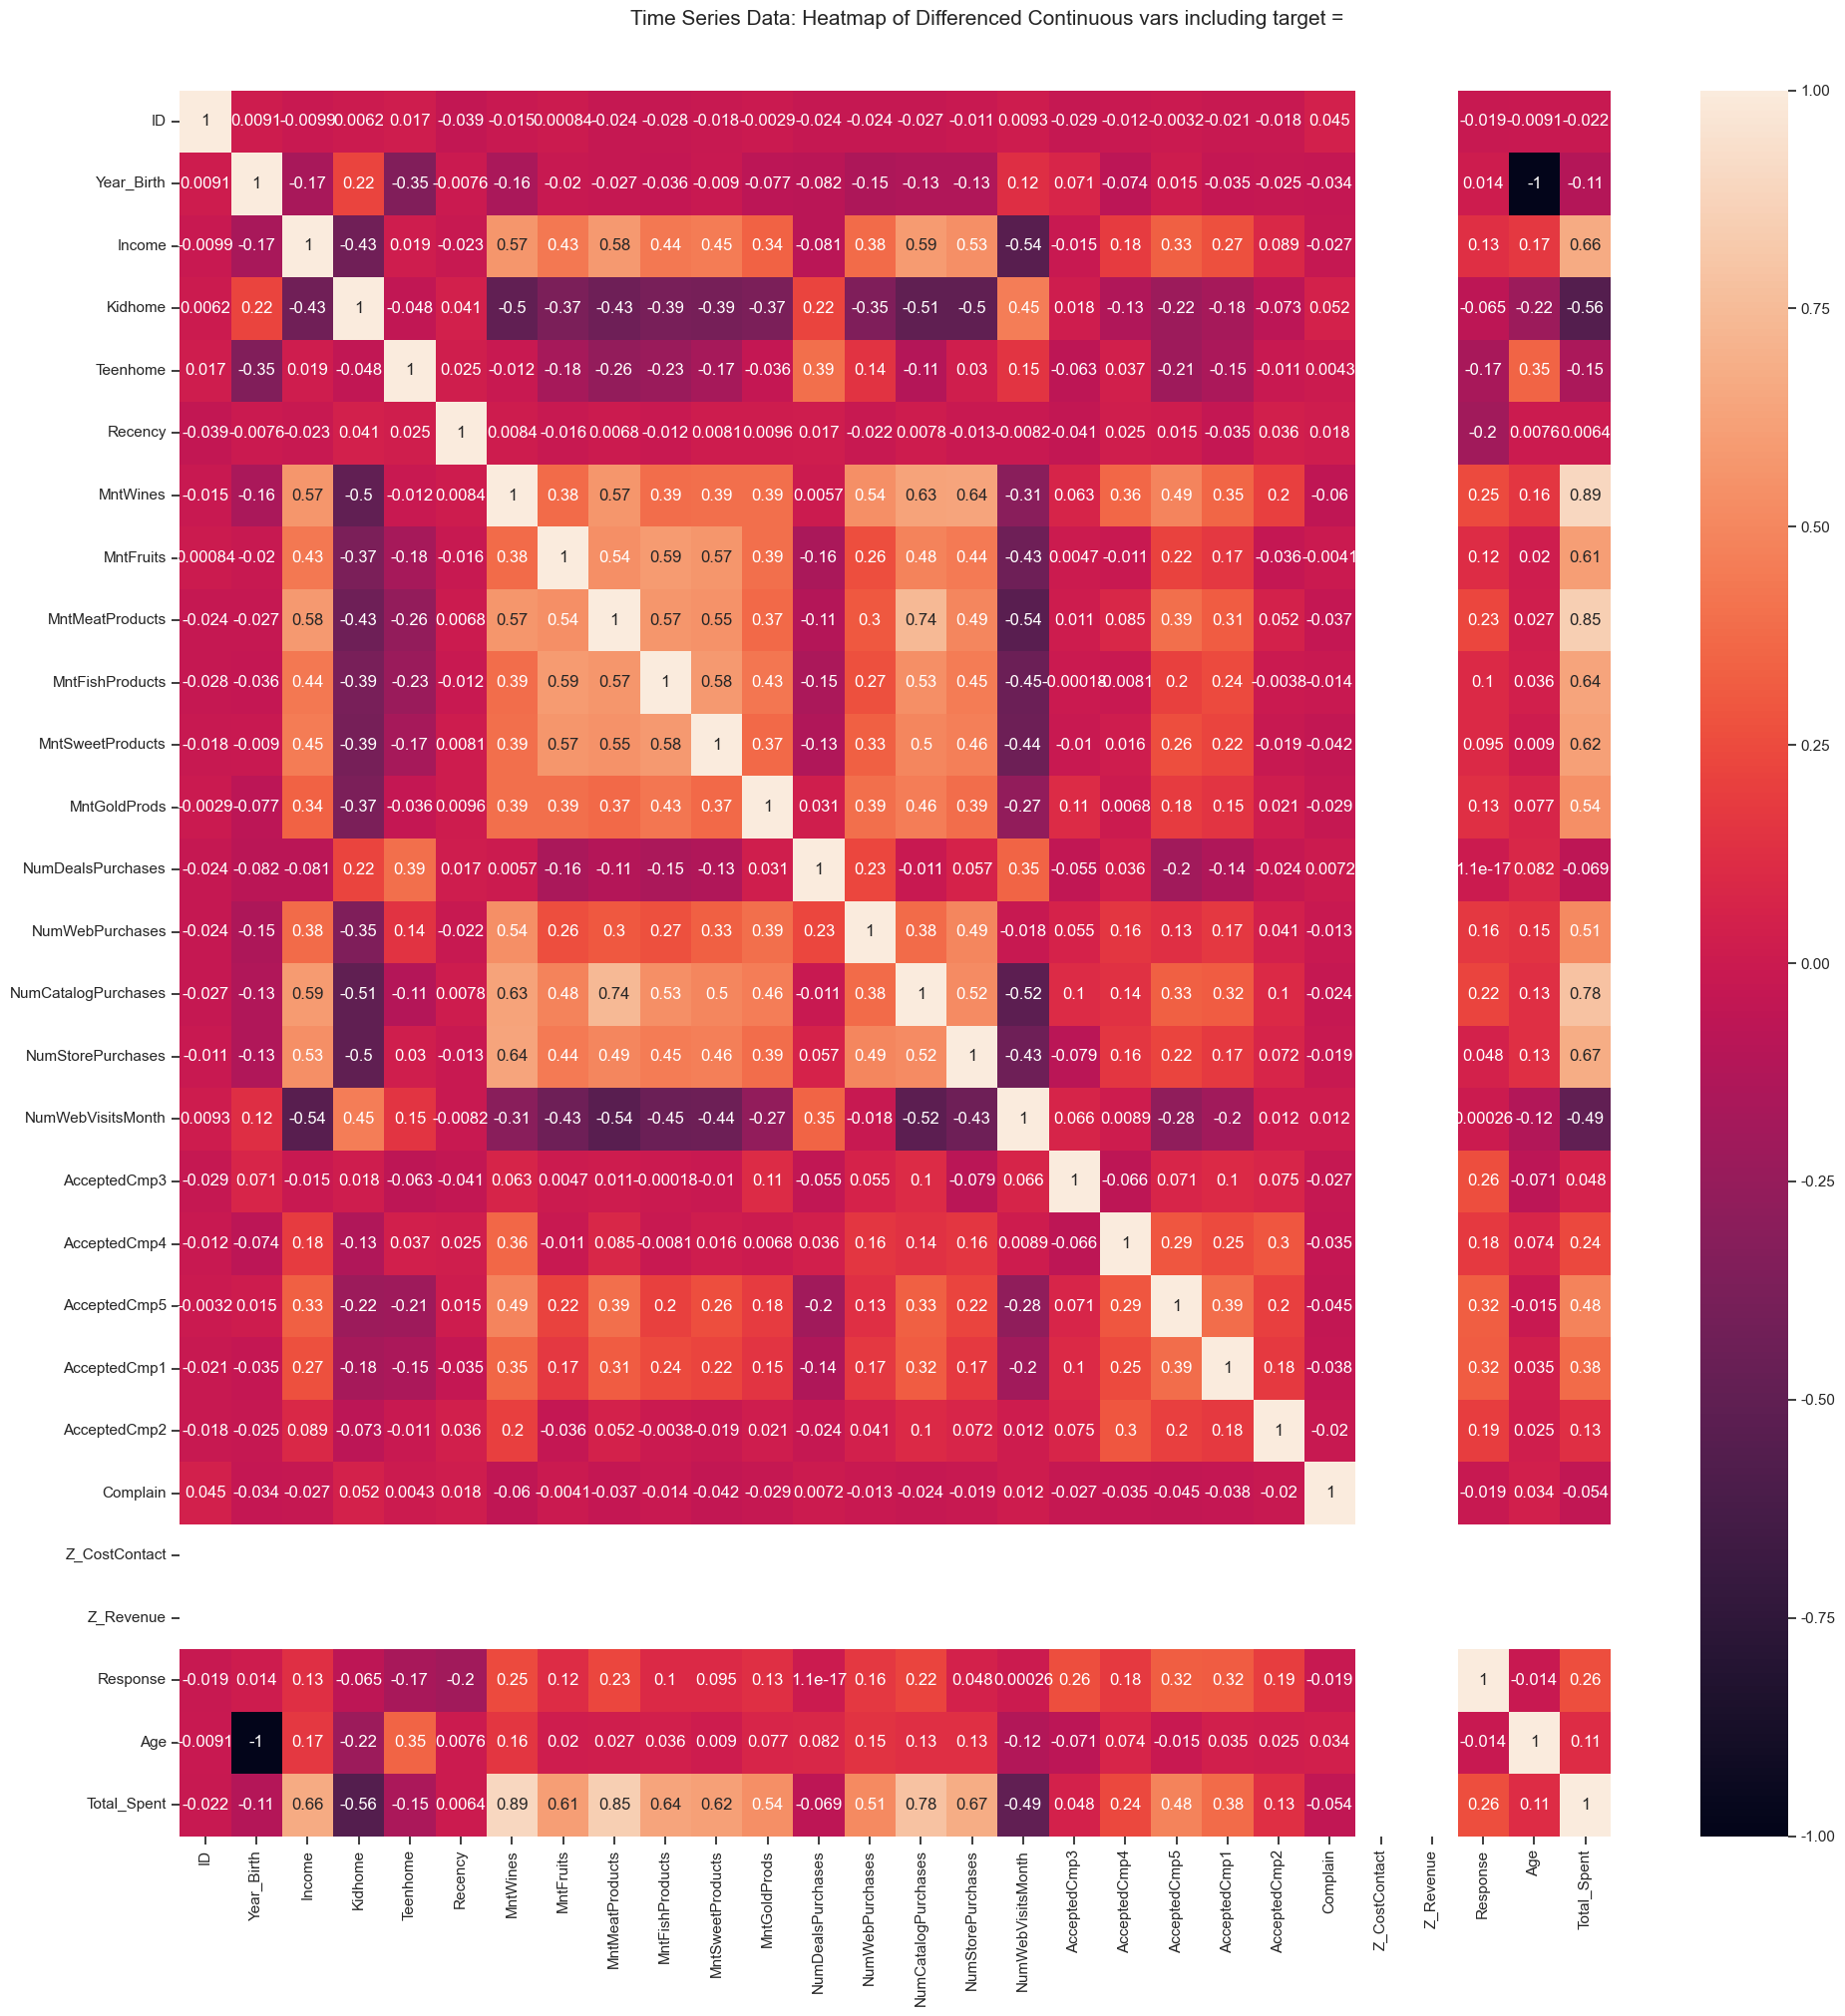

<Figure size 1500x0 with 0 Axes>

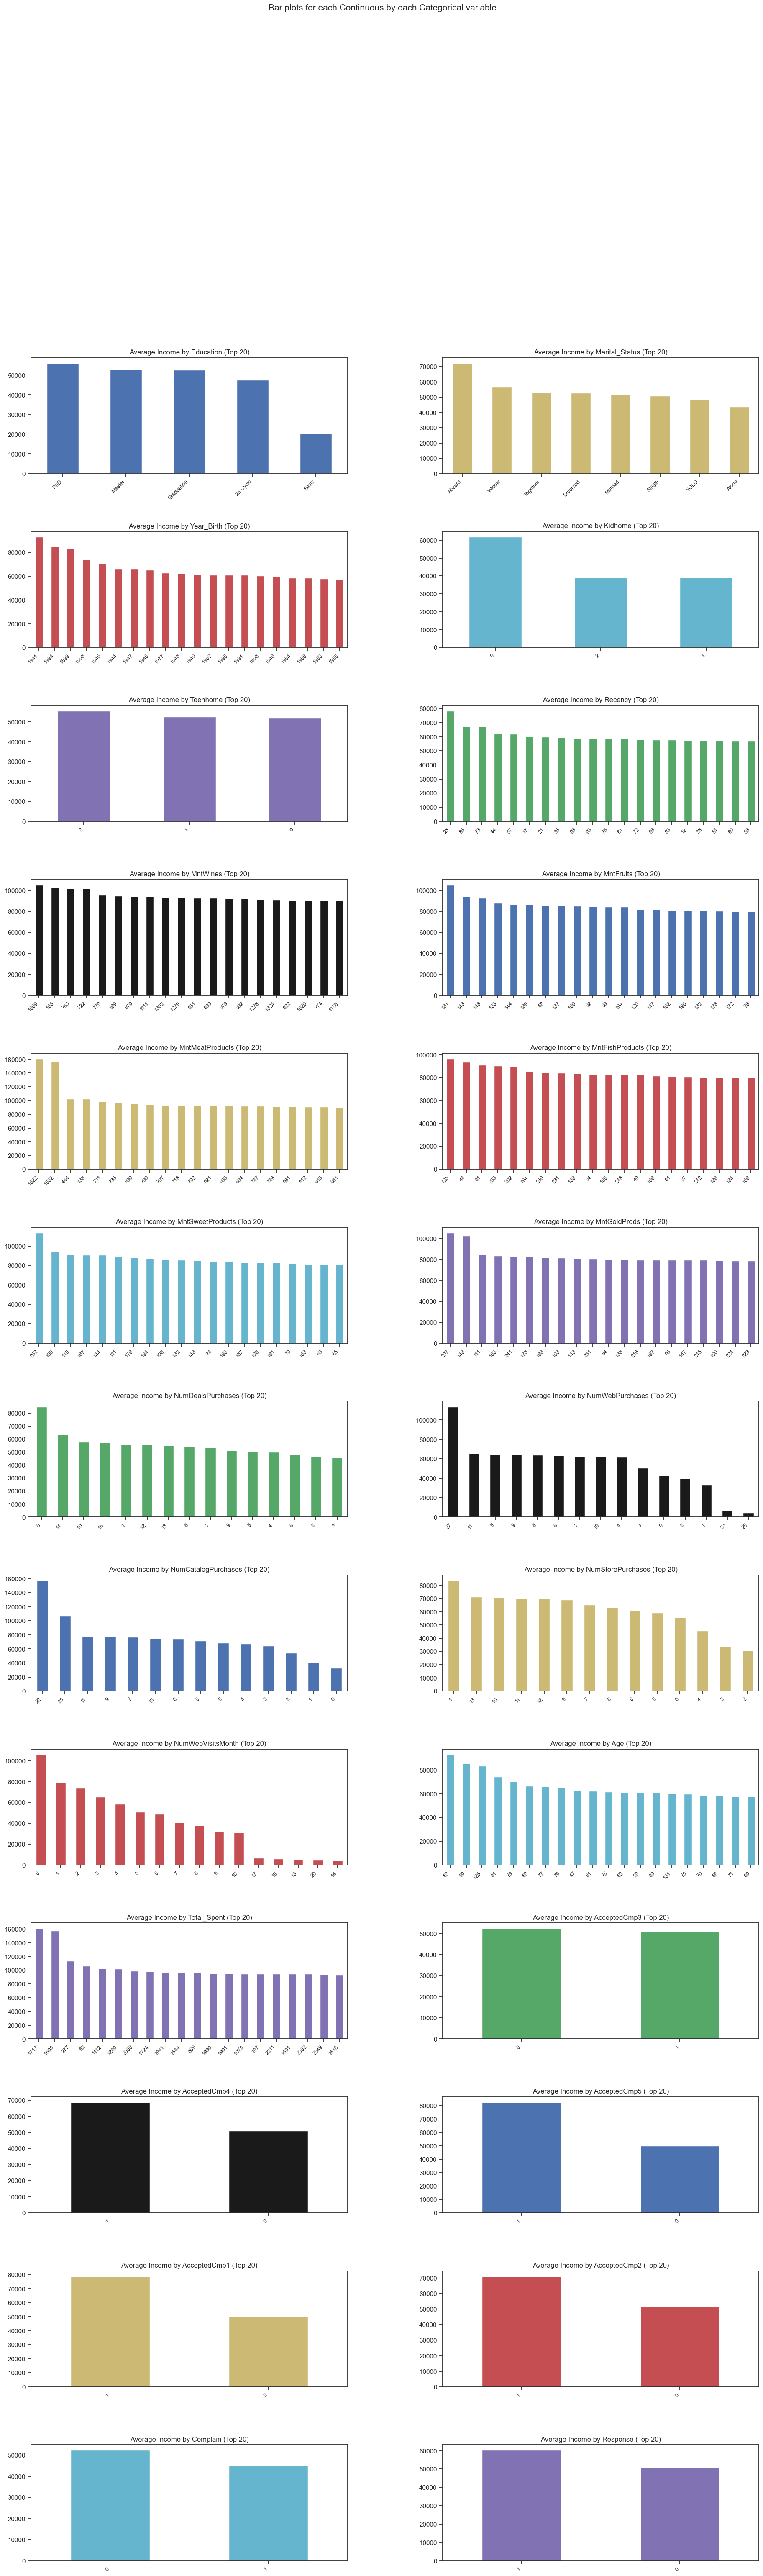

In [17]:
%matplotlib inline
try:
    from autoviz.AutoViz_Class import AutoViz_Class
    AV = AutoViz_Class()
    save_dir = OUT_DIR / "autoviz"; save_dir.mkdir(exist_ok=True)
    dft = AV.AutoViz(filename="", dfte=mk, depVar="", verbose=2, lowess=False,
                     chart_format="png", save_plot_dir=str(save_dir))
    print("Biểu đồ AutoViz đã lưu trong", save_dir)
except ImportError:
    print("Chưa cài autoviz: pip install autoviz")
except Exception as e:
    print("autoviz lỗi:", e)

## E. EDA thủ công trên Marketing Campaign (đối chứng với các công cụ tự động)
Phần này luôn chạy được, dùng để kiểm chứng/đối chiếu kết quả của SweetViz, AutoViz và làm ảnh minh họa cho báo cáo.

In [14]:
num = mk.select_dtypes(include="number").drop(columns=["ID", "Z_CostContact", "Z_Revenue"], errors="ignore")
print("Giá trị thiếu:"); display(mk.isna().sum()[mk.isna().sum() > 0].to_frame("missing"))
display(describe_full(mk[[c for c in ["Age", "Income", "Recency", "Total_Spent"] if c in mk.columns]]))
display(outlier_table(mk[[c for c in ["Age", "Income", "Total_Spent"] if c in mk.columns]]))

Giá trị thiếu:


,missing
Income,24


,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
Age,2240,0,55.194,54.0,48.0,11.984,1.436180e+02,28.0,131.0,103.0,47.00,65.0,18.00,0.350,0.717
Income,2216,24,52247.251,51381.5,7500.0,25173.077,6.336838e+08,1730.0,666666.0,664936.0,35303.00,68522.0,33219.00,6.763,159.637
Recency,2240,0,49.109,49.0,56.0,28.962,8.388240e+02,0.0,99.0,99.0,24.00,74.0,50.00,-0.002,-1.202
Total_Spent,2240,0,605.798,396.0,46.0,602.249,3.627042e+05,5.0,2525.0,2520.0,68.75,1045.5,976.75,0.861,-0.342


,column,lower_fence,upper_fence,n_outliers,outlier_%
0,Income,-14525.500,118350.500,8,0.36
1,Age,20.000,92.000,3,0.13
2,Total_Spent,-1396.375,2510.625,3,0.13


In [15]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axs[0], ["Age", "Income", "Total_Spent"]):
    if c in mk.columns: sns.histplot(mk[c], kde=True, ax=ax); ax.set_title(c)
for ax, c in zip(axs[1], ["Education", "Marital_Status"]):
    if c in mk.columns: sns.countplot(data=mk, y=c, ax=ax); ax.set_title(c)
if "Response" in mk.columns:
    sns.countplot(data=mk, x="Response", ax=axs[1, 2]); axs[1, 2].set_title("Response (phản hồi chiến dịch)")
save_fig("s13_marketing_univariate")

2026-10-19 16:13:59,576 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-19 16:13:59,583 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


[Đã lưu] figures\s13_marketing_univariate.png


In [16]:
corr_cols = [c for c in ["Age", "Income", "Recency", "Total_Spent", "NumWebPurchases", "NumStorePurchases",
                         "NumWebVisitsMonth", "Kidhome", "Teenhome", "Response"] if c in mk.columns]
plt.figure(figsize=(8, 6)); sns.heatmap(mk[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
save_fig("s13_marketing_corr")

inc = mk[mk["Income"] < mk["Income"].quantile(0.99)]  # bỏ ngoại lai thu nhập cực đoan để dễ nhìn
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=inc, x="Income", y="Total_Spent", alpha=.5, ax=axs[0])
if "Education" in mk.columns: sns.boxplot(data=mk, x="Education", y="Total_Spent", ax=axs[1]); axs[1].tick_params(axis="x", rotation=30)
save_fig("s13_marketing_bivariate")

[Đã lưu] figures\s13_marketing_corr.png
[Đã lưu] figures\s13_marketing_bivariate.png


## F. So sánh nhanh các công cụ EDA tự động (dùng cho báo cáo)
| Công cụ | Đầu ra | Điểm mạnh | Hạn chế |
|---|---|---|---|
| ydata-profiling | HTML (hoặc widget) | Báo cáo rất đầy đủ: thống kê, tương quan, missing, cảnh báo (alerts) | Chậm với dữ liệu lớn |
| dtale | Web app tương tác | Lọc, sắp xếp, vẽ biểu đồ, sửa dữ liệu trực tiếp bằng giao diện | Cần chạy server cục bộ |
| SweetViz | HTML | So sánh 2 tập dữ liệu (train/test) và phân tích theo biến mục tiêu rất trực quan | Ít cập nhật, có thể lỗi với phiên bản pandas/numpy mới |
| AutoViz | Ảnh/HTML | Tự chọn và vẽ biểu đồ phù hợp chỉ với 1 dòng lệnh, tự phát hiện ngoại lai | Ít tùy biến, nhiều biểu đồ cần lọc lại |